# Experiment 6 - Part 3: Index Configuration Benchmark and the Pinecone Equivalent

**Course:** HAAI302COM - Artificial Intelligence Laboratory

A vector database exposes settings that trade **latency**, **recall**, **memory** and **build time** against each other. The right setting depends on your data size and requirements, so engineers benchmark. In this notebook we do it properly:

1. build a collection of about 118,000 vectors and compute exact ground truth,
2. sweep the search-time knob `hnsw_ef`,
3. compare build-time settings `m` and `ef_construct`,
4. compare quantisation (int8, binary, product) with and without rescoring,
5. test filtered search at scale, with and without payload indexes,
6. measure throughput under parallel load,
7. see the same operations in **Pinecone**.

**Reading the numbers.** HNSW graphs are built by several threads in parallel, so two builds of the same data differ slightly, and recall values can change in the second decimal between runs. Latencies also vary with the machine. Compare rows within one run and treat differences of about 0.01 in recall or 0.5 ms in latency as noise.

Definitions used throughout: **recall@10** is the fraction of the exact top-10 neighbours that the database returns; **latency** is the wall-clock time of one search request as the client sees it (HTTP and JSON included), reported as median (p50) and 95th percentile (p95).

## 0. Setup and the benchmark corpus

As in Experiment 5, about 12,000 real vectors are too few to show scale effects, so we create about 118,000 synthetic vectors: ten random *blends* of each real paper with another random paper, plus noise. Each synthetic vector inherits the payload (`year`, `primary_category`) of its first parent, so filters behave realistically. The 200 query vectors are real vectors with a little noise.

In [1]:
import os, time, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 175)
pd.set_option("display.max_columns", 20)

from qdrant_client import QdrantClient, models
client = QdrantClient(url="http://localhost:6333", timeout=120)

papers = pd.read_json("data/arxiv_sample.jsonl", lines=True)
E = np.load("emb_arxiv.npy")                                   # saved by notebook 01
print(E.shape, "| papers:", len(papers))

(11762, 384) | papers: 11762


In [2]:
rng = np.random.default_rng(0)
copies = 10
n = len(E)
first = np.repeat(np.arange(n), copies)
second = rng.integers(0, n, size=n * copies)
w = rng.uniform(0.5, 1.0, size=(n * copies, 1)).astype("float32")
big = w * E[first] + (1 - w) * E[second]
big += rng.standard_normal(big.shape).astype("float32") * (0.1 / np.sqrt(E.shape[1]))
big = (big / np.linalg.norm(big, axis=1, keepdims=True)).astype("float32")

years = papers.year.values[first]
cats = papers.primary_category.values[first]
qi = rng.choice(n, 200, replace=False)
queries = E[qi] + rng.standard_normal((200, E.shape[1])).astype("float32") * (0.05 / np.sqrt(E.shape[1]))
queries = (queries / np.linalg.norm(queries, axis=1, keepdims=True)).astype("float32")
print("corpus:", big.shape, "|", round(big.nbytes / 1e6), "MB as float32 | queries:", queries.shape)

corpus: (117620, 384) | 181 MB as float32 | queries: (200, 384)


**Ground truth.** Exact top-10 for every query by brute force with NumPy. Everything the database returns is judged against this.

In [3]:
K = 10
t0 = time.time()
truth = np.argsort(-(queries @ big.T), axis=1)[:, :K]
print("exact search for 200 queries took", round(time.time() - t0, 2), "s ->", round((time.time() - t0) / 200 * 1000, 1), "ms per query with NumPy")

exact search for 200 queries took 1.9 s -> 9.5 ms per query with NumPy


## 1. Helpers: build a collection, measure latency and recall

`build` creates a collection with the chosen settings, uploads the 118,000 points with their payload and waits until the optimizer has finished indexing (status `green`). The time includes uploading and indexing. `bench` sends the 200 queries one at a time and records each request's duration.

In [4]:
def build(name, m=16, ef_construct=100, quant=None, on_disk=False):
    if client.collection_exists(name):
        client.delete_collection(name)
    client.create_collection(
        name,
        vectors_config=models.VectorParams(size=big.shape[1], distance=models.Distance.COSINE, on_disk=on_disk),
        hnsw_config=models.HnswConfigDiff(m=m, ef_construct=ef_construct),
        quantization_config=quant,
        optimizers_config=models.OptimizersConfigDiff(indexing_threshold=1000, default_segment_number=2),
    )
    pts = (models.PointStruct(id=i, vector=big[i].tolist(), payload={"year": int(years[i]), "primary_category": cats[i]}) for i in range(len(big)))
    t0 = time.time()
    client.upload_points(name, pts, batch_size=500, parallel=2, wait=True)
    while client.get_collection(name).status != models.CollectionStatus.GREEN:
        time.sleep(1)
    time.sleep(5)                                              # let background cleanup of earlier collections finish
    info = client.get_collection(name)
    return {"build_s": round(time.time() - t0, 1), "indexed": info.indexed_vectors_count, "segments": info.segments_count}

def bench(name, ef=None, quant_params=None, flt=None, truth_ids=None, vectors=queries):
    lat, rec = [], []
    sp = models.SearchParams(hnsw_ef=ef, quantization=quant_params)
    for qv in vectors:                                          # one untimed pass first: warms the OS cache and the connection pool
        client.query_points(name, query=qv.tolist(), query_filter=flt, limit=K, search_params=sp, with_payload=False)
    for qv, tr in zip(vectors, truth if truth_ids is None else truth_ids):
        t0 = time.perf_counter()
        res = client.query_points(name, query=qv.tolist(), query_filter=flt, limit=K, search_params=sp, with_payload=False).points
        lat.append((time.perf_counter() - t0) * 1000)
        rec.append(len({p.id for p in res} & set(tr)) / max(len(tr), 1))
    return {"p50_ms": round(float(np.percentile(lat, 50)), 2), "p95_ms": round(float(np.percentile(lat, 95)), 2), "recall@10": round(float(np.mean(rec)), 3)}

## 2. The baseline and the search-time knob `hnsw_ef`

We build the default configuration (`m=16`, `ef_construct=100`) and sweep `hnsw_ef`, the width of the graph search at query time (the equivalent of `efSearch` in FAISS). A larger value explores more candidates.

In [5]:
base_info = build("bench_base")
print(base_info)

{'build_s': 43.0, 'indexed': 117620, 'segments': 2}


In [6]:
rows = []
for ef in [8, 16, 32, 64, 128, 256]:
    rows.append({"hnsw_ef": ef, **bench("bench_base", ef=ef)})
ef_df = pd.DataFrame(rows)
ef_df

,hnsw_ef,p50_ms,p95_ms,recall@10
0,8,4.38,6.17,0.994
1,16,4.87,6.35,0.994
2,32,4.88,6.52,0.994
3,64,4.82,6.54,0.995
4,128,5.11,6.88,0.995
5,256,5.74,7.44,0.995


Before reading the table, we measure the **fixed cost of one request**: a call that does almost no work (counting the points). Whatever it costs is a floor under every latency we report.

In [7]:
lat = []
for _ in range(200):
    t0 = time.perf_counter(); client.count("bench_base", exact=False); lat.append((time.perf_counter() - t0) * 1000)
print("a trivial request (count) takes p50", round(float(np.percentile(lat, 50)), 2), "ms, p95", round(float(np.percentile(lat, 95)), 2), "ms")

a trivial request (count) takes p50 3.52 ms, p95 4.96 ms


**What to notice:** recall is already about 0.99 at `hnsw_ef=8` and stays near 0.995 up to `ef=256`, while the median latency rises only from about 4.4 to 5.7 ms across the whole sweep. Two reasons. This corpus is easy (blends of real papers form smooth neighbourhoods), and most of the 5 ms is the fixed cost of a request: a trivial `count` call takes about 3.5 ms at the median, so the search itself is only roughly 1 to 2 ms. On this data the search-time knob has little to trade; on harder data (more clusters, filters, higher dimensions) the curve bends more. Always report the request overhead beside latencies, otherwise differences between settings look smaller than they are.

## 3. Build-time knobs: `m` and `ef_construct`

These are fixed when the index is built; changing them means rebuilding. `m` is the number of links per node (a denser graph is easier to navigate but uses more memory), `ef_construct` is the search width used while inserting each point (a better graph, slower build). We build three variants and compare them at the same query-time `hnsw_ef=64`.

In [8]:
variants = {"m=8, ef_construct=50": (8, 50), "m=16, ef_construct=100 (default)": (16, 100), "m=32, ef_construct=200": (32, 200)}
rows = []
for label, (m, efc) in variants.items():
    name = f"bench_m{m}"                                       # every variant is freshly built, so none starts with a colder cache
    info = build(name, m=m, ef_construct=efc)
    r64 = bench(name, ef=64); r16 = bench(name, ef=16)
    rows.append({"config": label, "build_s": info["build_s"], "recall@10 (ef=16)": r16["recall@10"],
                 "recall@10 (ef=64)": r64["recall@10"], "p50_ms (ef=64)": r64["p50_ms"], "p95_ms (ef=64)": r64["p95_ms"]})
    client.delete_collection(name)
build_df = pd.DataFrame(rows)
build_df

,config,build_s,recall@10 (ef=16),recall@10 (ef=64),p50_ms (ef=64),p95_ms (ef=64)
0,"m=8, ef_construct=50",38.5,0.935,0.960,4.89,6.42
1,"m=16, ef_construct=100 (default)",41.5,0.989,0.995,5.12,6.52
2,"m=32, ef_construct=200",55.5,1.000,1.000,5.09,6.79


**What to notice:** build settings change recall, not latency. At `hnsw_ef=64` the recall is about 0.96 for `m=8`, 0.995 for `m=16` and 1.000 for `m=32`, while the median latency stays near 5 ms for all three. With a narrow search (`ef=16`) the gap is wider (about 0.93, 0.99 and 1.0): a denser graph is easier to navigate with few steps. The price is paid at build time (about 38, 42 and 56 seconds) and in memory for the graph links (not measured here). For this data the default is already enough, and `m=8` is the first setting that visibly loses recall.

## 4. Quantisation: shrinking the vectors

Quantisation keeps a compressed copy of each vector in RAM for fast scoring, while the full-precision vectors can stay on disk. The three methods:

| Method | Stored per vector (384 dims) | Compression |
|---|---|---|
| none | 1,536 bytes (float32) | 1x |
| **scalar int8** | 384 bytes | 4x |
| **binary** | 48 bytes (one bit per dimension) | 32x |
| **product** (x16) | about 96 bytes | 16x |

Compressed scores are approximate, so Qdrant can **rescore**: fetch more candidates than needed (`oversampling`), re-compute their exact scores with the original vectors and keep the best 10. We test each method with and without rescoring. The original vectors are put on disk (`on_disk=True`) to show the memory benefit.

In [9]:
quants = {
    "scalar int8": models.ScalarQuantization(scalar=models.ScalarQuantizationConfig(type=models.ScalarType.INT8, quantile=0.99, always_ram=True)),
    "binary": models.BinaryQuantization(binary=models.BinaryQuantizationConfig(always_ram=True)),
    "product x16": models.ProductQuantization(product=models.ProductQuantizationConfig(compression=models.CompressionRatio.X16, always_ram=True)),
}
ram_per_vec = {"none": 4 * big.shape[1], "scalar int8": big.shape[1], "binary": big.shape[1] // 8, "product x16": 4 * big.shape[1] // 16}

rows = [{"quantization": "none (float32, in RAM)", "rescore": "-", "oversampling": "-", "build_s": base_info["build_s"],
         "vector_RAM_MB": round(len(big) * ram_per_vec["none"] / 1e6), **bench("bench_base", ef=64)}]
for label, q in quants.items():
    name = "bench_q"
    info = build(name, quant=q, on_disk=True)
    for rescore, over in [(False, None), (True, 2.0), (True, 4.0)]:
        qp = models.QuantizationSearchParams(rescore=rescore, oversampling=over)
        rows.append({"quantization": label, "rescore": rescore, "oversampling": over, "build_s": info["build_s"],
                     "vector_RAM_MB": round(len(big) * ram_per_vec[label] / 1e6), **bench(name, ef=64, quant_params=qp)})
    client.delete_collection(name)
quant_df = pd.DataFrame(rows)
quant_df

,quantization,rescore,oversampling,build_s,vector_RAM_MB,p50_ms,p95_ms,recall@10
0,"none (float32, in RAM)",-,-,43.0,181,4.93,6.43,0.995
1,scalar int8,False,None,39.6,45,4.66,6.47,0.992
2,scalar int8,True,2.0,39.6,45,5.15,6.63,0.993
3,scalar int8,True,4.0,39.6,45,5.04,6.51,0.993
4,binary,False,None,39.4,6,4.95,6.56,0.968
5,binary,True,2.0,39.4,6,4.97,6.40,0.996
6,binary,True,4.0,39.4,6,4.90,6.44,0.998
7,product x16,False,None,147.7,11,5.20,6.71,0.983
8,product x16,True,2.0,147.7,11,5.29,6.71,0.997
9,product x16,True,4.0,147.7,11,5.41,6.88,0.997


**What to notice:** **Scalar int8** gives 4 times less vector RAM (45 MB instead of 181 MB) with no visible recall loss (about 0.99 against 0.995), with or without rescoring. **Binary** gives 30 times less (6 MB), costs recall when used alone (about 0.97), and with rescoring at oversampling 2 recovers to about 0.996 to 0.998, the same as unquantised search. **Product x16** is 16 times smaller, reaches about 0.98 alone and 0.997 with rescoring, and takes about 3.5 times longer to build (about 148 seconds against 43) because it trains codebooks. Latency does not improve: every row is near 5 ms, because at this size the request overhead dominates and the data fits in RAM anyway. Quantisation here buys memory, not speed. Rescoring adds roughly 0.3 to 0.6 ms. Binary quantisation is, according to Qdrant's documentation, mainly recommended for higher-dimensional embeddings than our 384; the table shows that at this size it needs rescoring to be safe.

## 5. The trade-off in one picture

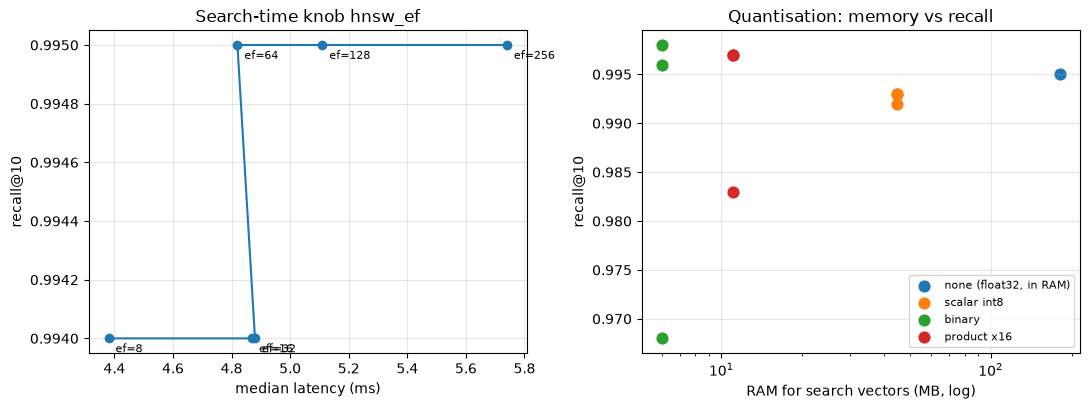

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.plot(ef_df["p50_ms"], ef_df["recall@10"], marker="o")
for _, r in ef_df.iterrows():
    ax.annotate(f"ef={int(r.hnsw_ef)}", (r.p50_ms, r["recall@10"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.set_xlabel("median latency (ms)"); ax.set_ylabel("recall@10"); ax.set_title("Search-time knob hnsw_ef"); ax.grid(alpha=0.3)
ax = axes[1]
for label, g in quant_df.groupby("quantization", sort=False):
    ax.scatter(g["vector_RAM_MB"], g["recall@10"], label=label, s=60)
ax.set_xscale("log"); ax.set_xlabel("RAM for search vectors (MB, log)"); ax.set_ylabel("recall@10"); ax.set_title("Quantisation: memory vs recall"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice:** the left panel shows how flat the `hnsw_ef` trade-off is on this data: the whole curve spans roughly 1.5 ms and 0.001 of recall. In the right panel, moving left (less RAM) costs recall only for the binary and product points without rescoring; the rescored versions climb back to 0.99 or higher. The practical recipe that this picture supports: quantise to save RAM, keep the original vectors on disk and turn rescoring on.

## 6. Filtered search at scale

Part 2 showed filters on 11,762 points. Here we repeat on about 118,000 with three filters of decreasing selectivity (fraction of points passing): `year >= 1995` (broad), `year >= 2015` (medium) and `year >= 2015` AND one rare category (very selective). The ground truth is exact search restricted to the matching points. We measure the default collection before and after creating payload indexes.

In [11]:
def exact_filtered(mask):
    idx = np.where(mask)[0]
    sims = queries @ big[idx].T
    return idx[np.argsort(-sims, axis=1)[:, :K]]

rare_cat = pd.Series(cats).value_counts().index[12]
F = models.FieldCondition
cases = {
    "broad: year >= 1995": (models.Filter(must=[F(key="year", range=models.Range(gte=1995))]), years >= 1995),
    "medium: year >= 2015": (models.Filter(must=[F(key="year", range=models.Range(gte=2015))]), years >= 2015),
    f"narrow: year >= 2015 and {rare_cat}": (models.Filter(must=[F(key="year", range=models.Range(gte=2015)), F(key="primary_category", match=models.MatchValue(value=rare_cat))]), (years >= 2015) & (cats == rare_cat)),
}
for label, (_, mask) in cases.items():
    print(f"{label:45s} passes {mask.mean():.2%} ({mask.sum()} points)")

broad: year >= 1995                           passes 99.01% (116450 points)
medium: year >= 2015                          passes 49.94% (58740 points)
narrow: year >= 2015 and math.CO              passes 1.11% (1310 points)


In [12]:
gts = {label: exact_filtered(mask) for label, (_, mask) in cases.items()}
rows = []
for label, (flt, mask) in cases.items():
    rows.append({"filter": label, "payload index": "no", **bench("bench_base", ef=64, flt=flt, truth_ids=gts[label])})
client.create_payload_index("bench_base", "year", models.PayloadSchemaType.INTEGER, wait=True)
client.create_payload_index("bench_base", "primary_category", models.PayloadSchemaType.KEYWORD, wait=True)
for label, (flt, mask) in cases.items():
    rows.append({"filter": label, "payload index": "yes", **bench("bench_base", ef=64, flt=flt, truth_ids=gts[label])})
filt_df = pd.DataFrame(rows)
filt_df

,filter,payload index,p50_ms,p95_ms,recall@10
0,broad: year >= 1995,no,6.22,8.26,0.995
1,medium: year >= 2015,no,6.51,8.20,0.870
2,narrow: year >= 2015 and math.CO,no,185.67,187.43,1.000
3,broad: year >= 1995,yes,5.46,6.90,0.995
4,medium: year >= 2015,yes,5.59,7.12,0.870
5,narrow: year >= 2015 and math.CO,yes,5.52,7.10,1.000


**What to notice:** the payload index matters most for the **narrow** filter: 1,310 matching points take about 186 ms per query without an index and about 5.5 ms with one, roughly 34 times faster, because without the index the engine must read candidate payloads one by one to evaluate the condition. For the broad and medium filters the index changes little. Look at recall too: it is about 0.996 for the broad filter, 1.000 for the narrow one (a small set is scanned exactly) and only **about 0.87 for the medium filter**. Filters that keep about half of the points are the hardest case for a graph index here, because years correlate with topics and the filter cuts the graph into pieces.

The medium filter has lower recall than the others. Does a wider search help? We sweep `hnsw_ef` for that filter (payload indexes in place).

In [13]:
flt_m, mask_m = cases["medium: year >= 2015"]
pd.DataFrame([{"hnsw_ef": ef, **bench("bench_base", ef=ef, flt=flt_m, truth_ids=gts["medium: year >= 2015"])} for ef in [64, 128, 256, 512]])

,hnsw_ef,p50_ms,p95_ms,recall@10
0,64,5.49,7.01,0.870
1,128,5.45,6.97,0.922
2,256,5.65,7.27,0.942
3,512,6.67,8.16,0.960


**What to notice:** a wider search repairs part of the loss: recall rises from about 0.87 at `hnsw_ef=64` to 0.92, 0.94 and 0.96 at 128, 256 and 512, while the median latency grows from about 5.5 to 6.7 ms. So filtered queries often need a larger `hnsw_ef` than unfiltered ones. Always measure recall per type of filter, not only for the unfiltered case.

## 7. Throughput under parallel load

Latency is one request; **throughput** (queries per second, QPS) is how many the server completes per second when many clients ask at once. We send the 200 queries from 1, 4 and 16 client threads.

In [14]:
from concurrent.futures import ThreadPoolExecutor
sp = models.SearchParams(hnsw_ef=64)

def one(qv):
    t0 = time.perf_counter()
    client.query_points("bench_base", query=qv.tolist(), limit=K, search_params=sp, with_payload=False)
    return (time.perf_counter() - t0) * 1000

rows = []
for threads in [1, 4, 16]:
    t0 = time.perf_counter()
    with ThreadPoolExecutor(threads) as ex:
        lat = list(ex.map(one, list(queries) * 2))
    wall = time.perf_counter() - t0
    rows.append({"client threads": threads, "QPS": round(len(lat) / wall), "p50_ms": round(float(np.percentile(lat, 50)), 1), "p95_ms": round(float(np.percentile(lat, 95)), 1)})
pd.DataFrame(rows)

,client threads,QPS,p50_ms,p95_ms
0,1,195,5.1,6.8
1,4,295,13.3,19.4
2,16,286,54.3,70.0


**What to notice:** one client thread sustains about 195 queries per second at 5 ms per request. Four threads reach about 295 (1.5 times more) and latency grows to about 13 ms; sixteen threads do not add throughput (about 286) and the median latency rises to 54 ms, which is simply queueing: threads divided by QPS gives the latency (16 / 286 is about 56 ms). Throughput saturates near 300 queries per second in this setup. The Python client (GIL, JSON) may be as much of a bottleneck as the server, so treat this as a lower bound; a real load test uses gRPC and a compiled load generator.

## 8. The same knowledge base in Pinecone

**Pinecone** is a fully managed vector database: you do not run a server or choose HNSW parameters; you create an *index* through an API key. The concepts map one to one:

| Qdrant | Pinecone |
|---|---|
| collection | index (and **namespaces** inside it to separate data) |
| point: id, vector, payload | record: id, values, metadata |
| `query_points(..., query_filter=Filter(...))` | `index.query(vector=..., filter={...})` |
| `FieldCondition(range=Range(gte=2015))` | `{"year": {"$gte": 2015}}` |
| `MatchAny` / `must` / `should` | `{"$in": [...]}` / `$and` / `$or` |
| `upsert` / `delete` / `count` | `upsert` / `delete` / `describe_index_stats` |
| tuning `m`, `ef_construct`, `hnsw_ef`, quantisation | not exposed; you choose the index type and capacity |
| self-hosted (Docker), or Qdrant Cloud | hosted only |

The cell below runs the equivalent workflow **only if** a `PINECONE_API_KEY` environment variable is set (create a free account to get one). Otherwise it prints a message and does nothing, so the notebook runs for everyone. It reuses the first 1,000 papers so that a free tier is enough, and deletes the index at the end.

In [15]:
key = os.environ.get("PINECONE_API_KEY")
if not key:
    print("PINECONE_API_KEY not set: skipping the live Pinecone demo (the code below is what would run).")
else:
    from pinecone import Pinecone, ServerlessSpec
    pc = Pinecone(api_key=key)
    name = "lab-arxiv"
    if name not in pc.list_indexes().names():
        pc.create_index(name=name, dimension=E.shape[1], metric="cosine", spec=ServerlessSpec(cloud="aws", region="us-east-1"))
        while not pc.describe_index(name).status["ready"]:
            time.sleep(2)
    index = pc.Index(name)

    records = [{"id": str(i), "values": E[i].tolist(),
                "metadata": {"year": int(papers.year[i]), "primary_category": papers.primary_category[i], "title": papers.title[i][:200]}} for i in range(1000)]
    for s in range(0, len(records), 200):
        index.upsert(vectors=records[s:s + 200], namespace="papers")
    time.sleep(10)                                       # serverless indexes are eventually consistent
    print(index.describe_index_stats())

    res = index.query(vector=queries[0].tolist(), top_k=5, namespace="papers", include_metadata=True,
                      filter={"year": {"$gte": 2005}, "primary_category": {"$in": ["cs.CL", "cs.LG", "stat.ML"]}})
    for m in res.matches:
        print(round(m.score, 3), m.metadata["year"], m.metadata["primary_category"], m.metadata["title"][:70])
    pc.delete_index(name)                                # free the quota

PINECONE_API_KEY not set: skipping the live Pinecone demo (the code below is what would run).


**What to notice:** the Pinecone code has the same shape as the Qdrant code (create, upsert records with metadata, query with a filter), only the filter syntax and the vocabulary differ. What you give up is control of the index settings that sections 2 to 4 tuned; what you gain is no infrastructure. Practical differences to check in the documentation before choosing: metadata size limits per record, consistency after upserts (the pause above), pricing at your data size, and whether your data may leave your network.

## Clean up

In [16]:
for name in ["bench_base"]:
    if client.collection_exists(name):
        client.delete_collection(name)
print("remaining collections:", [c.name for c in client.get_collections().collections])

remaining collections: ['arxiv', 'pdf_chunks', 'toy']


## Summary

| Knob | Set when | Raises | Costs |
|---|---|---|---|
| `hnsw_ef` | each query | recall | latency |
| `m` | index build | recall at a given `hnsw_ef`, robustness with filters | memory, build time |
| `ef_construct` | index build | graph quality | build time |
| quantisation + rescore | index build (rescore per query) | memory savings (4x to 32x) | some recall unless rescored, extra latency for rescoring |
| payload index | any time | filter speed and filtered recall | a little memory and write time |

**How to benchmark your own system:** fix a query set and exact ground truth, sweep one knob at a time, report recall together with p50 and p95 latency, and choose the cheapest configuration that meets your recall target.

**Experiment 6 complete.** You built a Qdrant knowledge base from structured and unstructured data (Part 1), queried it with metadata filters (Part 2) and benchmarked index configurations, with the Pinecone equivalent (Part 3).